# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubrafathima2005-kf/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

### Ranked Actions and Reason Codes

I will rank pages using the Random Forest model trained with the grouped client split from Week 6. The score represents the measured likelihood of the declining label in this dataset.

Each page will receive a reason code and a suggested action:

- REFRESH_REVIEW: Pages aged 91–180 days with moderate or good impressions. Review whether the content needs updating.
- LOW_VISIBILITY: Pages with low impressions. Investigate search visibility and content relevance.
- NEW_CONTENT: Pages aged 0–30 days. Monitor before making major changes.
- OLDER_CONTENT: Pages aged over 180 days. Check whether the content is still useful.
- GENERAL_REVIEW: Pages that do not fit the above groups.

The ranking is a review queue, not an instruction to automatically change content.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

# Load the anonymized dataset
url = "https://raw.githubusercontent.com/kubrafathima2005-kf/flyrank-ml-internship/main/data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(url)

df["is_declining_label"] = (
    df["trend_direction"] == "down"
).astype(int)

# Same metadata features used in Week 6
numeric_features = [
    "search_volume", "competition", "cpc",
    "word_count", "char_count"
]

categorical_features = [
    "content_type", "main_intent", "competition_level"
]

features = numeric_features + categorical_features
X = df[features]
y = df["is_declining_label"]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Grouped split by client
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df["client_id"])
)

# Train only on training clients
model.fit(X.iloc[train_idx], y.iloc[train_idx])

# Rank held-out client pages
queue = df.iloc[test_idx].copy()
queue["model_score"] = model.predict_proba(
    X.iloc[test_idx]
)[:, 1]

# Assign reason codes and suggested actions
def assign_reason(row):
    if row["freshness_tier"] == "91-180" and row["impression_tier"] in ["moderate", "good"]:
        return "REFRESH_REVIEW"
    elif row["impression_tier"] == "low":
        return "LOW_VISIBILITY"
    elif row["freshness_tier"] == "0-30":
        return "NEW_CONTENT"
    elif row["freshness_tier"] == "181+":
        return "OLDER_CONTENT"
    else:
        return "GENERAL_REVIEW"

queue["reason_code"] = queue.apply(assign_reason, axis=1)

action_map = {
    "REFRESH_REVIEW": "Review content for possible updates",
    "LOW_VISIBILITY": "Investigate search visibility",
    "NEW_CONTENT": "Monitor before major changes",
    "OLDER_CONTENT": "Check continued usefulness",
    "GENERAL_REVIEW": "Manual content review"
}

queue["suggested_action"] = queue["reason_code"].map(action_map)

queue = queue.sort_values(
    "model_score", ascending=False
).reset_index(drop=True)

queue["rank"] = range(1, len(queue) + 1)

print("Ranked queue rows:", len(queue))
print("\nReason code counts:")
print(queue["reason_code"].value_counts())

print("\nTop 10 ranked actions:")
print(queue[
    ["rank", "model_score", "reason_code", "suggested_action"]
].head(10))

Ranked queue rows: 6163

Reason code counts:
reason_code
LOW_VISIBILITY    2818
NEW_CONTENT       2636
REFRESH_REVIEW     647
GENERAL_REVIEW      62
Name: count, dtype: int64

Top 10 ranked actions:
   rank  model_score     reason_code                     suggested_action
0     1          1.0  LOW_VISIBILITY        Investigate search visibility
1     2          1.0  REFRESH_REVIEW  Review content for possible updates
2     3          1.0  LOW_VISIBILITY        Investigate search visibility
3     4          1.0     NEW_CONTENT         Monitor before major changes
4     5          1.0  REFRESH_REVIEW  Review content for possible updates
5     6          1.0  LOW_VISIBILITY        Investigate search visibility
6     7          1.0     NEW_CONTENT         Monitor before major changes
7     8          1.0  LOW_VISIBILITY        Investigate search visibility
8     9          1.0     NEW_CONTENT         Monitor before major changes
9    10          1.0  LOW_VISIBILITY        Investigate searc

In [2]:
print("Unique model scores:", queue["model_score"].nunique())
print("\nScore distribution:")
print(queue["model_score"].describe())

print("\nPages with score 1.0:",
      (queue["model_score"] == 1.0).sum())

Unique model scores: 855

Score distribution:
count    6163.000000
mean        0.566891
std         0.212712
min         0.000000
25%         0.400000
50%         0.570000
75%         0.730000
max         1.000000
Name: model_score, dtype: float64

Pages with score 1.0: 27


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


### Intended Use

This action playbook is designed to help content editors identify pages that may need attention. It ranks pages using model scores and assigns reason codes with suggested actions.

The ranked queue is intended for human review and decision-support. Editors can use it to decide which pages to investigate first.

### Limitations

The model was tested on a limited dataset of 32 clients. Its grouped validation Precision@50 was 0.40, so its performance on unseen clients is not yet reliable enough for automatic decisions.

The model uses content and keyword metadata. It does not understand the full meaning, quality, or business value of a page.

A high score does not guarantee that a page is declining or needs refreshing. All recommendations must be checked by a human editor.

## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

### Human Review Rules

Before taking action, a human editor must:

1. Read the page and check whether its information is accurate.
2. Check search performance and traffic trends.
3. Verify whether the content is outdated or incomplete.
4. Check business importance and user needs.
5. Approve any proposed content changes.

### What Should NOT Be Automated

- Publishing or deleting content.
- Rewriting pages without human approval.
- Changing prices, legal, medical, or financial information.
- Removing pages based only on model scores.
- Making final business decisions automatically.

The model only suggests which pages may need attention. A human editor makes the final decision.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

### Monitoring and Retraining Triggers

The model should be monitored regularly to check whether its recommendations remain useful.

Monitoring should include:

1. Check Precision@50 using newly reviewed and labelled pages.
2. Track the number of pages in each reason code.
3. Check whether the data distribution changes over time.
4. Compare model performance with the Week 6 grouped validation result.

Retraining should be considered when:

- New labelled data becomes available.
- Model performance decreases.
- The dataset or label definition changes.
- Important changes occur in the input data.

Retraining should use grouped or time-based validation to avoid overly optimistic results.

The model should remain a human-review tool. It should not make automatic content decisions.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

### Exports for the Research Paper

The notebook exports the ranked action queue, model evaluation metrics, and a reason-code chart.

The ranked queue is saved as a CSV file in `work/outputs/`. This file can be regenerated by running the notebook and is not committed to GitHub.

The reason-code chart is saved in `work/figures/` so it can be reused in the research paper.

The metrics JSON is saved as evidence of the model's evaluation results.

These exports help editors and researchers understand the model's recommendations and limitations.

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


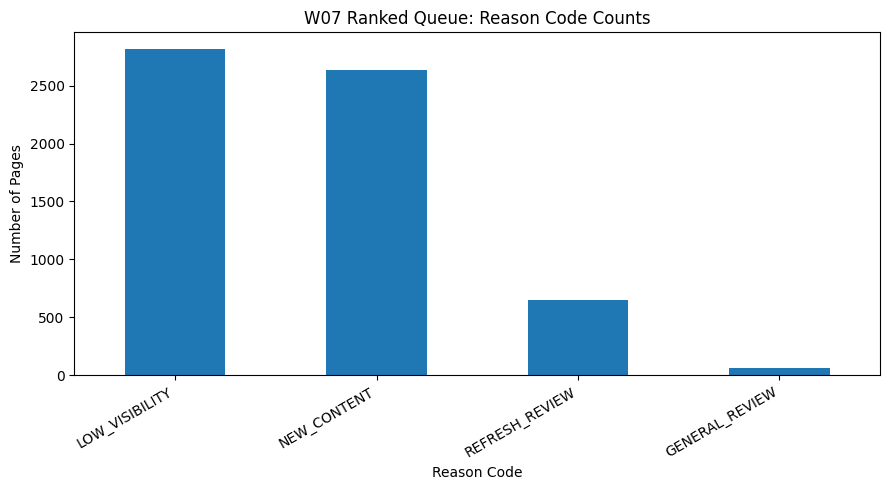

Exports created successfully!
Queue CSV: work/outputs/w07_ranked_action_queue.csv
Metrics: work/outputs/w07_metrics.json
Figure: work/figures/w07_reason_code_counts.png


In [3]:
import os
import json
import matplotlib.pyplot as plt

# Create folders
os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

# 1. Export ranked action queue
queue.to_csv(
    "work/outputs/w07_ranked_action_queue.csv",
    index=False
)

# 2. Save model metrics
metrics = {
    "validation_method": "Grouped client split",
    "test_clients": int(df.iloc[test_idx]["client_id"].nunique()),
    "test_rows": int(len(queue)),
    "unique_model_scores": int(queue["model_score"].nunique()),
    "mean_model_score": float(queue["model_score"].mean()),
    "reason_code_counts": {
        str(k): int(v)
        for k, v in queue["reason_code"].value_counts().items()
    }
}

with open("work/outputs/w07_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# 3. Save reason-code chart
reason_counts = queue["reason_code"].value_counts()

plt.figure(figsize=(9, 5))
reason_counts.plot(kind="bar")
plt.title("W07 Ranked Queue: Reason Code Counts")
plt.xlabel("Reason Code")
plt.ylabel("Number of Pages")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(
    "work/figures/w07_reason_code_counts.png",
    dpi=300
)
plt.show()

print("Exports created successfully!")
print("Queue CSV: work/outputs/w07_ranked_action_queue.csv")
print("Metrics: work/outputs/w07_metrics.json")
print("Figure: work/figures/w07_reason_code_counts.png")

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.

### Self-Check

- [x] Ranked action queue generated.
- [x] Reason codes assigned to pages.
- [x] Intended use and limitations documented.
- [x] Human review rules documented.
- [x] Monitoring and retraining triggers documented.
- [x] Queue CSV exported.
- [x] Metrics JSON exported.
- [x] Reason-code chart saved.

The action playbook is a decision-support tool. All content actions require human review.